# RBM+TDVP vs exact ED: mu, T, R^2, infidelity

Scans every saved RBM+TDVP run under `../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_*.npz`
(produced by `rbm_tdvp_quench.py` / `rbm_tdvp_quench_scan.py`), recomputes the matching
exact-ED cluster-expansion fit ($\mu$, $T$, $R^2$ from the Fermi-Dirac fit
of rank vs $\log|c_A|$, as in `cumulants_time_evolution.ipynb`), and plots
them side by side with the RBM+TDVP infidelity vs exact for the same
quench. Re-running this notebook automatically picks up any new runs
saved since the last execution.

In [1]:
import os
import glob
import sys
sys.path.append('../ClusterExpansion/')
sys.path.append('.')

import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LogNorm

import cluster_expansion as ce
import ed_definitions as ed

## Shared Fermi-Dirac fit machinery (same as `cumulants_time_evolution.ipynb`)

In [2]:
def fermi_dirac(x, mu, T):
    return 1024 / (np.exp((x - mu) / T) + 1)

noise_floor = -28.0  # log|c_A| below this is Z2-symmetry-forced machine-precision noise

def rank_vs_logc(c_A_row):
    """Sort |c_A| descending, drop numerical-noise entries, return (log|c_A|, rank)."""
    absvals = np.abs(c_A_row)
    with np.errstate(divide='ignore'):
        log_c_all = np.log(absvals)
    real_sorted = np.sort(absvals[log_c_all > noise_floor])[::-1]
    log_c = np.log(real_sorted)
    rank = np.arange(1, len(real_sorted) + 1)
    return log_c, rank

def compute_ed_grid(L, J, g_i, J2, gz, theta, pbc, g_f_values, times):
    """Exact-ED mu(t,g_f), T(t,g_f), R^2(t,g_f) for the given quench family."""
    n_times = len(times)
    _, hi, H_i = ed.build_TFI_hamiltonian_2(L, g_i, J, J2, gz=gz, theta=theta, pbc=pbc)
    psi0 = ed.ground_state(H_i)[1]

    mu_grid = np.full((len(g_f_values), n_times), np.nan)
    T_grid = np.full((len(g_f_values), n_times), np.nan)
    R2_grid = np.full((len(g_f_values), n_times), np.nan)

    for i, g_f in enumerate(g_f_values):
        _, _, H_f = ed.build_TFI_hamiltonian_2(L, g_f, J, J2, gz=gz, theta=theta, pbc=pbc)
        evals, evecs = ed.full_diagonalization(H_f)
        psi_t = ed.evolve_state(evals, evecs, psi0, times)
        p0 = [-10.0, 3.0]
        for k in range(n_times):
            logabs = np.log(np.abs(psi_t[k]))
            c_A_row = np.real(ce.fwht_coeffs_in_cluster_col_order(logabs, hi))
            log_c, rank = rank_vs_logc(c_A_row)
            try:
                popt, _ = curve_fit(fermi_dirac, log_c, rank, p0=p0, maxfev=20000)
                mu_grid[i, k] = popt[0]
                T_grid[i, k] = popt[1]
                pred = fermi_dirac(log_c, *popt)
                R2_grid[i, k] = 1 - np.sum((rank - pred) ** 2) / np.sum((rank - rank.mean()) ** 2)
                p0 = popt
            except RuntimeError:
                pass
    return mu_grid, T_grid, R2_grid

def load_or_compute_ed_grid(fpath, ed_ce_dir, L, J, g_i, J2, gz, theta, pbc, g_f_values, times):
    """Load the precomputed ED grid for this run from ED_CE/ if it exists,
    otherwise compute it and cache it there for next time."""
    cache_path = f'{ed_ce_dir}/{os.path.basename(fpath)}'
    if os.path.exists(cache_path):
        c = np.load(cache_path)
        return c['mu_grid'], c['T_grid'], c['R2_grid']

    mu_grid, T_grid, R2_grid = compute_ed_grid(L, J, g_i, J2, gz, theta, pbc, g_f_values, times)
    os.makedirs(ed_ce_dir, exist_ok=True)
    np.savez(cache_path, mu_grid=mu_grid, T_grid=T_grid, R2_grid=R2_grid,
             g_f_values=g_f_values, times=times, L=L, J=J, g_i=g_i, J2=J2, gz=gz, theta=theta, pbc=pbc)
    return mu_grid, T_grid, R2_grid

## Discover all saved RBM+TDVP runs

Matches `rbm_tdvp_quench.py`'s output (`rbm_tdvp_quench.npz`) and every
`rbm_tdvp_quench_scan.py` run (`rbm_tdvp_scan_*.npz`), now saved under the
shared top-level `../data/cumulants_Fermi_dirac_TDVP/` folder. Excludes the
`rbm_opt_only_*.npz` learning-rate-scan diagnostics, which have no TDVP
data to compare.

In [3]:
data_dir = '../data/cumulants_Fermi_dirac_TDVP'
ed_ce_dir = f'{data_dir}/ED_CE'
run_files = sorted(glob.glob(f'{data_dir}/rbm_tdvp_*.npz'))
print(f"Found {len(run_files)} RBM+TDVP runs:")
for f in run_files:
    print(' ', f)

Found 6 RBM+TDVP runs:
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_quench.npz
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_scan_J2_0.5_gz_0.3_fine.npz
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_scan_J2_0.7_gz_0.4_fine.npz
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_scan_quench_gf0.4.npz
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_scan_theta0.2pi_fine.npz
  ../data/cumulants_Fermi_dirac_TDVP/rbm_tdvp_scan_theta0.2pi_gf0.npz


## Compare each run to its matching exact-ED $\mu$, $T$, $R^2$

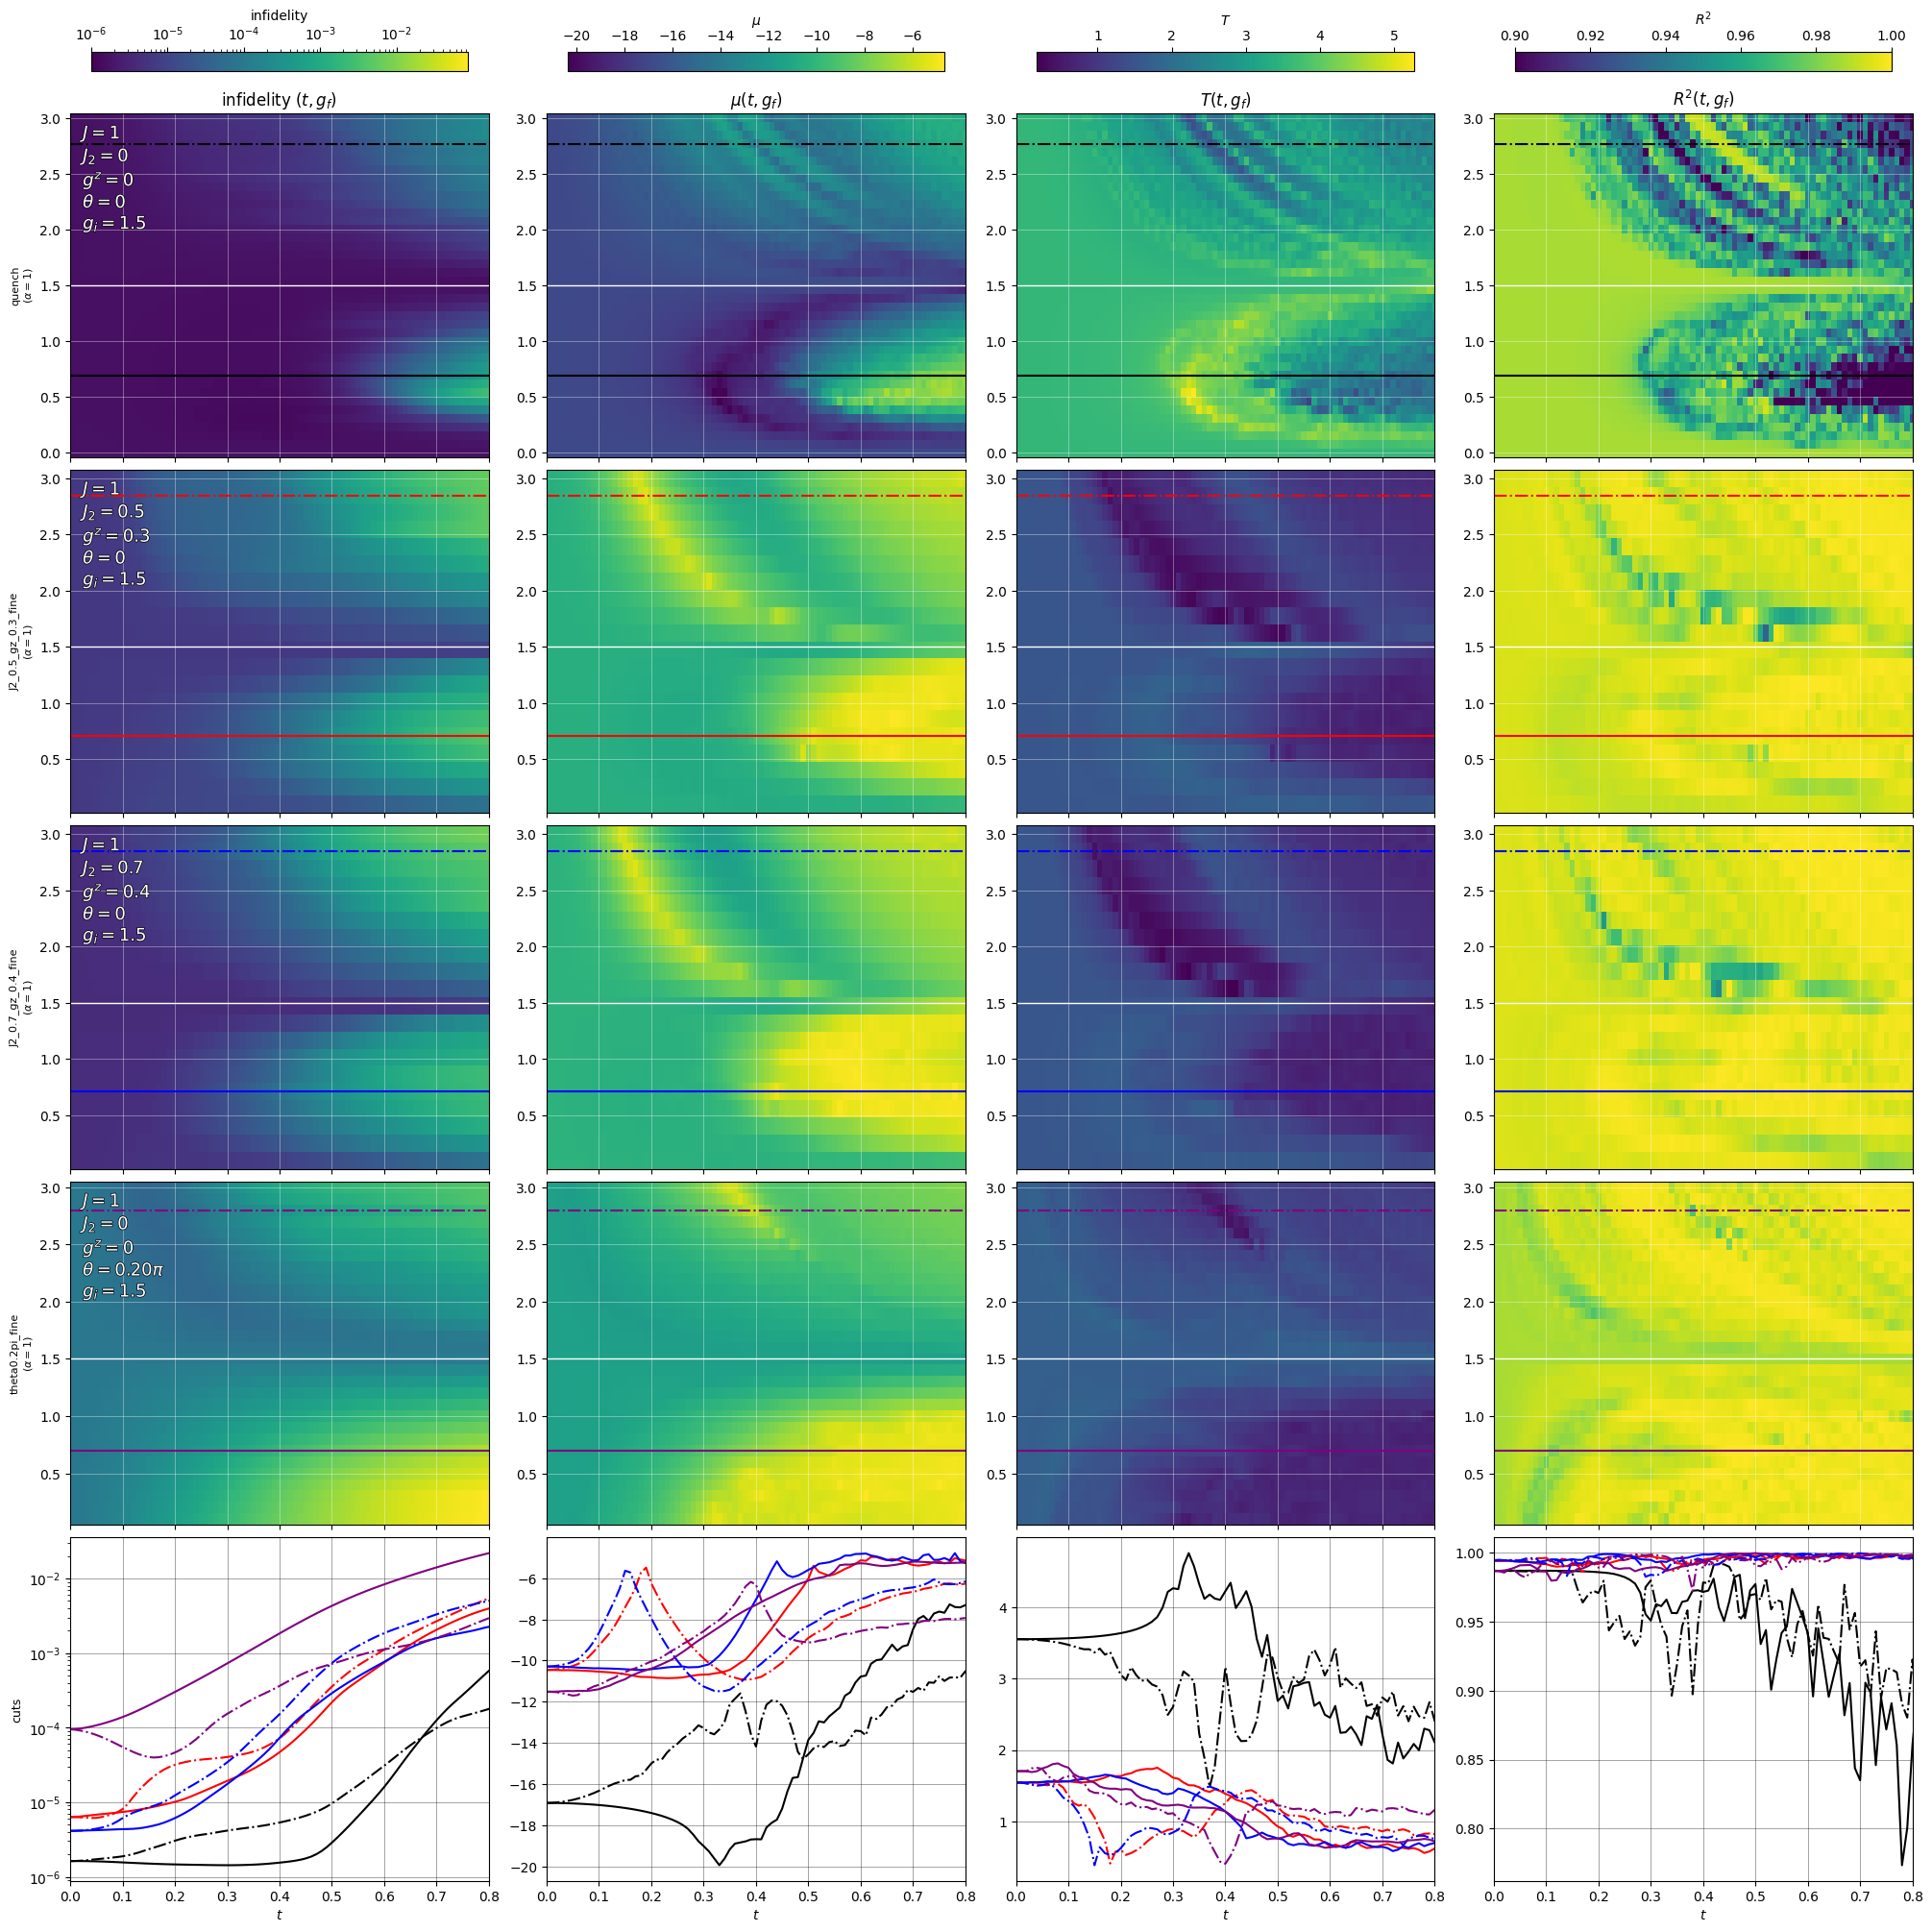

In [4]:
SHARED_COLORBAR = True  # True: one colorbar per column, shared scale across all runs.
                        # False: each subplot gets its own colorbar/scale.
PARAM_FONTSIZE = 13     # font size of the on-plot Hamiltonian-parameter text
PARAM_OUTLINE_WIDTH = 1.0  # black outline (stroke) width around that text

CUT_POSITIONS = [0.7, 2.8]           # g_f positions to cut, shared by every row -- just edit this list
# CUT_LINESTYLES = ['--', ':']         # one per entry in CUT_POSITIONS
CUT_LINESTYLES = ['-', '-.']         # one per entry in CUT_POSITIONS
ROW_COLORS = ['black', 'red', 'blue', 'purple', 'brown','darkorange',]  # one per heatmap row, cycled if more exist

GRID_X = True   # gridlines along the t (x) axis, in every panel
GRID_Y = True   # gridlines along the y axis (g_f for heatmaps, value for the cuts row)
GRID_COLOR_HEATMAP = 'white'  # grid color on top of the pcolormesh panels
GRID_COLOR_LINE = 'black'      # grid color on the bottom cuts row (white background)
GRID_ALPHA = 0.5
GRID_LW = 0.5

def apply_grid(ax, color, zorder=None):
    kw = dict(color=color, alpha=GRID_ALPHA, lw=GRID_LW)
    if zorder is not None:
        kw['zorder'] = zorder
    if GRID_X:
        ax.grid(axis='x', **kw)
    if GRID_Y:
        ax.grid(axis='y', **kw)

col_titles = ['infidelity $(t, g_f)$', r'$\mu(t, g_f)$', r'$T(t, g_f)$', r'$R^2(t, g_f)$']
cbar_labels = ['infidelity', r'$\mu$', r'$T$', r'$R^2$']

runs_data = []
for fpath in run_files:
    d = np.load(fpath)
    L = int(d['L']); J = float(d['J']); g_i = float(d['g_i']); pbc = bool(d['pbc'])
    alpha = int(d['alpha'])
    J2 = float(d['J2']) if 'J2' in d else 0.0
    gz = float(d['gz']) if 'gz' in d else 0.0
    theta = float(d['theta']) if 'theta' in d else 0.0
    g_f_values = d['g_f_values']
    if len(g_f_values) < 2:
        continue  # dedicated single-g_f runs are superseded by the automatic per-row cuts below
    times = d['times']
    infid_grid = d['infidelity_vs_exact']
    init_infid = float(d['initial_infidelity'])

    mu_grid, T_grid, R2_grid = load_or_compute_ed_grid(
        fpath, ed_ce_dir, L, J, g_i, J2, gz, theta, pbc, g_f_values, times)
    # T_grid = 1/T_grid  # convert from 1/T to T for plotting
    tag = os.path.basename(fpath).replace('rbm_tdvp_scan_', '').replace('rbm_tdvp_', '').replace('.npz', '') or 'quench'
    theta_math = f"{theta/np.pi:.2f}\\pi" if theta != 0 else "0"
    label = f"{tag}\n" + rf"($\alpha={alpha}$)"
    param_str = (rf"$J={J:g}$" + "\n" + rf"$J_2={J2:g}$" + "\n" + rf"$g^z={gz:g}$" + "\n"
                 + rf"$\theta={theta_math}$" + "\n" + rf"$g_i={g_i:g}$")

    runs_data.append(dict(g_f_values=g_f_values, times=times, infid_grid=infid_grid,
                           mu_grid=mu_grid, T_grid=T_grid, R2_grid=R2_grid, g_i=g_i,
                           label=label, param_str=param_str, tag=tag))

n_runs = len(runs_data)
for i, r in enumerate(runs_data):
    r['color'] = ROW_COLORS[i % len(ROW_COLORS)]
    # nearest actual g_f grid point to each requested cut position
    r['cut_idx'] = [int(np.argmin(np.abs(r['g_f_values'] - pos))) for pos in CUT_POSITIONS]

# global per-column scales, used only when SHARED_COLORBAR is True
infid_vmax = max(1e-2, max(np.nanmax(r['infid_grid']) for r in runs_data))
infid_vmin = 1e-6
mu_vmin = min(np.nanmin(r['mu_grid']) for r in runs_data)
mu_vmax = max(np.nanmax(r['mu_grid']) for r in runs_data)
T_vmin = min(np.nanmin(r['T_grid']) for r in runs_data)
T_vmax = max(np.nanmax(r['T_grid']) for r in runs_data)
R2_vmin, R2_vmax = 0.9, 1.0

# common t-axis range across every run, so the bottom cuts row lines up with the heatmap rows above
t_min = min(r['times'].min() for r in runs_data)
# t_max_shared = max(r['times'].max() for r in runs_data)
t_max_shared = min(r['times'].max() for r in runs_data)

outline = [pe.withStroke(linewidth=PARAM_OUTLINE_WIDTH, foreground='black')]

n_rows = n_runs + 1  # + 1 combined "cuts" row at the bottom

# constrained_layout (not tight_layout) is required for correct spacing when a
# colorbar is attached to a list of axes spanning multiple rows.
# sharex='col' keeps every row's t-axis (including the bottom cuts row) locked to the
# same range, even though individual runs may have different t_max/dt.
fig, axs = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows), squeeze=False, constrained_layout=True,
                         sharex='col')
col_im_for_cbar = [None] * 4

for row, r in enumerate(runs_data):
    axs[row, 0].set_ylabel(r['label'], fontsize=8)

    kwargs = [
        dict(norm=LogNorm(vmin=infid_vmin, vmax=infid_vmax)) if SHARED_COLORBAR
        else dict(norm=LogNorm(vmin=1e-6, vmax=max(1e-2, np.nanmax(r['infid_grid'])))),
        dict(vmin=mu_vmin, vmax=mu_vmax) if SHARED_COLORBAR else {},
        dict(vmin=T_vmin, vmax=T_vmax) if SHARED_COLORBAR else {},
        dict(vmin=R2_vmin, vmax=R2_vmax),
    ]
    grids = [r['infid_grid'], r['mu_grid'], r['T_grid'], r['R2_grid']]
    for col, (grid, kw) in enumerate(zip(grids, kwargs)):
        im = axs[row, col].pcolormesh(r['times'], r['g_f_values'], grid, shading='auto', cmap='viridis', **kw)
        axs[row, col].axhline(r['g_i'], color='white', ls='-', lw=1)
        for idx, ls in zip(r['cut_idx'], CUT_LINESTYLES):
            axs[row, col].axhline(r['g_f_values'][idx], color=r['color'], ls=ls, lw=1.5)
        apply_grid(axs[row, col], GRID_COLOR_HEATMAP, zorder=3)
        col_im_for_cbar[col] = im
        if not SHARED_COLORBAR:
            fig.colorbar(im, ax=axs[row, col], label=cbar_labels[col])

    # Hamiltonian parameters, one per line, top-left corner of the first (infidelity) panel
    axs[row, 0].text(0.03, 0.97, r['param_str'], transform=axs[row, 0].transAxes,
                      ha='left', va='top', fontsize=PARAM_FONTSIZE, color='white', path_effects=outline)

    if row == 0:
        for col, title in enumerate(col_titles):
            axs[row, col].set_title(title)

# combined bottom row: every row's cuts overlaid per column (color = row, linestyle = position)
cuts_row = n_rows - 1
axs[cuts_row, 0].set_ylabel('cuts', fontsize=9)
for r in runs_data:
    for idx, ls in zip(r['cut_idx'], CUT_LINESTYLES):
        gf_actual = r['g_f_values'][idx]
        axs[cuts_row, 0].plot(r['times'], r['infid_grid'][idx], ls=ls, color=r['color'],
                               label=rf"{r['tag']} $g_f={gf_actual:.2f}$")
        axs[cuts_row, 1].plot(r['times'], r['mu_grid'][idx], ls=ls, color=r['color'])
        axs[cuts_row, 2].plot(r['times'], r['T_grid'][idx], ls=ls, color=r['color'])
        axs[cuts_row, 3].plot(r['times'], r['R2_grid'][idx], ls=ls, color=r['color'])
axs[cuts_row, 0].set_yscale('log')
# axs[cuts_row, 0].legend(fontsize=7)
for col in range(4):
    apply_grid(axs[cuts_row, col], GRID_COLOR_LINE)
    axs[cuts_row, col].set_xlim(t_min, t_max_shared)

for col in range(4):
    axs[n_rows - 1, col].set_xlabel('$t$')

if SHARED_COLORBAR:
    for col in range(4):
        if col_im_for_cbar[col] is not None:
            fig.colorbar(col_im_for_cbar[col], ax=axs[0, col], orientation='horizontal',
                         location='top', label=cbar_labels[col], shrink=0.9)

plt.show()

## Entanglement entropy for the plain quench ($J=1$, $J_2=g^z=\theta=0$, $g_i=1.5$)

Half-chain von Neumann entanglement entropy $S(t,g_f)$, computed only from the exact ED time evolution (no RBM/TDVP involved), on the same $(t,g_f)$ grid as the `quench` row above.

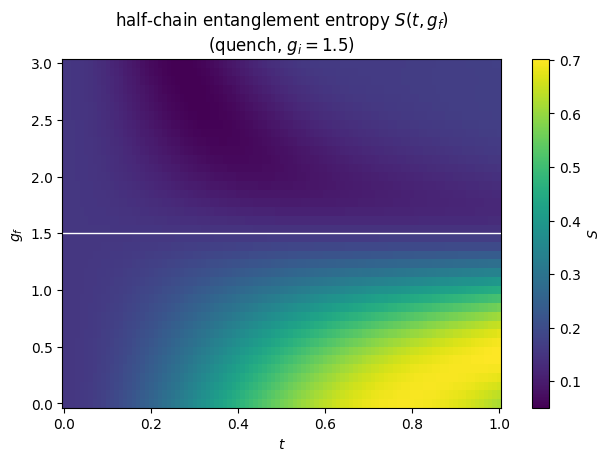

In [5]:
quench_fpath = f'{data_dir}/rbm_tdvp_quench.npz'
dq = np.load(quench_fpath)
L_q = int(dq['L']); J_q = float(dq['J']); g_i_q = float(dq['g_i']); pbc_q = bool(dq['pbc'])
g_f_values_q = dq['g_f_values']
times_q = dq['times']

ee_cache_path = f'{ed_ce_dir}/ee_{os.path.basename(quench_fpath)}'
if os.path.exists(ee_cache_path):
    ee_grid = np.load(ee_cache_path)['ee_grid']
else:
    _, hi_q, H_i_q = ed.build_TFI_hamiltonian_2(L_q, g_i_q, J_q, 0.0, gz=0.0, theta=0.0, pbc=pbc_q)
    psi0_q = ed.ground_state(H_i_q)[1]

    ee_grid = np.full((len(g_f_values_q), len(times_q)), np.nan)
    for i, g_f in enumerate(g_f_values_q):
        _, _, H_f_q = ed.build_TFI_hamiltonian_2(L_q, g_f, J_q, 0.0, gz=0.0, theta=0.0, pbc=pbc_q)
        evals_q, evecs_q = ed.full_diagonalization(H_f_q)
        psi_t_q = ed.evolve_state(evals_q, evecs_q, psi0_q, times_q)
        for k in range(len(times_q)):
            ee_grid[i, k] = ed.entanglement_entropy(psi_t_q[k], L_q)

    os.makedirs(ed_ce_dir, exist_ok=True)
    np.savez(ee_cache_path, ee_grid=ee_grid, g_f_values=g_f_values_q, times=times_q,
              L=L_q, J=J_q, g_i=g_i_q, pbc=pbc_q)

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
im = ax.pcolormesh(times_q, g_f_values_q, ee_grid, shading='auto', cmap='viridis')
ax.axhline(g_i_q, color='white', ls='-', lw=1)
ax.set_xlabel('$t$')
ax.set_ylabel('$g_f$')
ax.set_title(r'half-chain entanglement entropy $S(t, g_f)$' + f'\n(quench, $g_i={g_i_q:g}$)')
fig.colorbar(im, ax=ax, label='$S$')
plt.show()

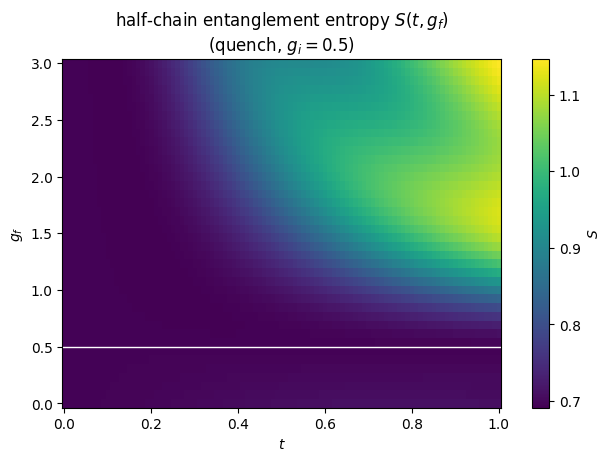

In [6]:
g_i_2 = 0.5

ee_cache_path_2 = f'{ed_ce_dir}/ee_gi{g_i_2:g}_{os.path.basename(quench_fpath)}'
if os.path.exists(ee_cache_path_2):
    ee_grid_2 = np.load(ee_cache_path_2)['ee_grid']
else:
    _, hi_q2, H_i_q2 = ed.build_TFI_hamiltonian_2(L_q, g_i_2, J_q, 0.0, gz=0.0, theta=0.0, pbc=pbc_q)
    psi0_q2 = ed.ground_state(H_i_q2)[1]

    ee_grid_2 = np.full((len(g_f_values_q), len(times_q)), np.nan)
    for i, g_f in enumerate(g_f_values_q):
        _, _, H_f_q2 = ed.build_TFI_hamiltonian_2(L_q, g_f, J_q, 0.0, gz=0.0, theta=0.0, pbc=pbc_q)
        evals_q2, evecs_q2 = ed.full_diagonalization(H_f_q2)
        psi_t_q2 = ed.evolve_state(evals_q2, evecs_q2, psi0_q2, times_q)
        for k in range(len(times_q)):
            ee_grid_2[i, k] = ed.entanglement_entropy(psi_t_q2[k], L_q)

    os.makedirs(ed_ce_dir, exist_ok=True)
    np.savez(ee_cache_path_2, ee_grid=ee_grid_2, g_f_values=g_f_values_q, times=times_q,
              L=L_q, J=J_q, g_i=g_i_2, pbc=pbc_q)

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
im = ax.pcolormesh(times_q, g_f_values_q, ee_grid_2, shading='auto', cmap='viridis')
ax.axhline(g_i_2, color='white', ls='-', lw=1)
ax.set_xlabel('$t$')
ax.set_ylabel('$g_f$')
ax.set_title(r'half-chain entanglement entropy $S(t, g_f)$' + f'\n(quench, $g_i={g_i_2:g}$)')
fig.colorbar(im, ax=ax, label='$S$')
plt.show()